# Vortex Panel Methods in 2D
### Constant-strength and linear-strength vortex panel methods: implementation, verification and limitations

**Author:** *(your name, roll number)*   **Course:** *(course code)*   **Submitted:** 8 November 2026

---

**Contents**
1. Algorithms
2. Implementation in Python
3. Verification on a circular cylinder
4. Verification on symmetric and cambered airfoils
5. Prediction of airfoil characteristics
6. Limitations of prediction: effect of thickness
7. References and acknowledgements

**Notation** (Anderson, *Fundamentals of Aerodynamics*, Sec. 4.10)

| Symbol | Meaning |
|---|---|
| $(X_j, Y_j)$ | boundary points (panel end points), clockwise from the trailing edge, lower surface first |
| $(x_i, y_i)$ | control points (panel midpoints) |
| $S_j,\ \phi_j$ | length and angle of panel $j$ |
| $\beta_i = \phi_i + \pi/2 - \alpha$ | angle between $V_\infty$ and the outward normal $n_i$ |
| $\gamma$ | vortex strength per unit length (clockwise positive) |
| $\theta_{ij}$ | angle $\tan^{-1}[(y_i - y_j)/(x_i - x_j)]$ from a point on panel $j$ to control point $i$ |
| $J_{ij} = \int_j \partial\theta_{ij}/\partial n_i\, ds_j$ | normal influence of panel $j$ at control point $i$ |
| $K_{ij} = \int_j \partial\theta_{ij}/\partial s_i\, ds_j$ | tangential influence of panel $j$ at control point $i$ |
| $J'_{ij} = \int_j (s_j/S_j)\,\partial\theta_{ij}/\partial n_i\, ds_j$ | weighted normal influence (linear panels) |

## 1. Algorithms

The airfoil surface is replaced by $N$ straight panels joined at $N+1$ boundary points. Each panel carries a vortex sheet. The sheet strengths are chosen so that

* the surface is a streamline: the normal velocity is zero at each control point, and
* the Kutta condition holds: the flow leaves the trailing edge smoothly, $\gamma(\text{TE}) = 0$.

The normal velocity induced at control point $i$ by a vortex sheet on panel $j$ is $-\frac{1}{2\pi}\int_j \gamma(s_j)\, \frac{\partial \theta_{ij}}{\partial n_i}\, ds_j$, and the freestream contributes $V_\infty \cos\beta_i$. Differentiating $\theta_{ij}$ gives the integrands

$$\frac{\partial\theta_{ij}}{\partial n_i} = \frac{(x_i - x_j)\cos\phi_i + (y_i - y_j)\sin\phi_i}{(x_i-x_j)^2 + (y_i-y_j)^2}, \qquad
\frac{\partial\theta_{ij}}{\partial s_i} = \frac{(x_i - x_j)\sin\phi_i - (y_i - y_j)\cos\phi_i}{(x_i-x_j)^2 + (y_i-y_j)^2},$$

where $(x_j, y_j) = (X_j + s_j\cos\phi_j,\; Y_j + s_j\sin\phi_j)$ moves along panel $j$.

### Algorithm 1: constant-strength vortex panel method (`vortex_panel_method_0`)

**Input:** boundary points $(X_j, Y_j)$, $j = 1,\dots,N+1$ (clockwise, closed); $\alpha$; $V_\infty$.
**Output:** $\gamma_j$, $V_i$, $C_{p,i}$, $\Gamma$, $c_l$.

1. **Geometry.** For each panel $j = 1,\dots,N$: $S_j = \sqrt{(X_{j+1}-X_j)^2 + (Y_{j+1}-Y_j)^2}$, $\phi_j = \operatorname{atan2}(Y_{j+1}-Y_j,\, X_{j+1}-X_j)$, control point $(x_j, y_j)$ at the panel midpoint, and $\beta_j = \phi_j + \pi/2 - \alpha$.
2. **Influence coefficients.** For every pair $i \ne j$, evaluate $J_{ij}$ and $K_{ij}$ by numerical quadrature. For $i = j$ the principal-value integrals vanish: $J_{ii} = K_{ii} = 0$.
3. **Flow tangency.** For $i = 1,\dots,N$: $\displaystyle\sum_{j=1}^{N} J_{ij}\,\gamma_j = 2\pi V_\infty\cos\beta_i$.
4. **Kutta condition.** $\gamma_1 + \gamma_N = 0$. This gives $N+1$ equations for $N$ unknowns, so the last tangency equation is discarded and replaced by the Kutta condition (Anderson's procedure).
5. **Solve** the $N\times N$ system for $\gamma_j$. *Remedy for ill-conditioning (Section 4.2):* the matrix has a nearly singular "sawtooth" mode $\gamma = (+a, -a, +a, \dots)$. The system is solved by singular value decomposition, $A = U\Sigma V^T$, keeping every mode except the one with the smallest singular value.
6. **Surface velocity.** $\displaystyle V_i = V_\infty\sin\beta_i - \sum_{j} \frac{\gamma_j}{2\pi} K_{ij} + \frac{\gamma_i}{2}$, where $\gamma_i/2$ is the outer-side jump across the sheet. Then $C_{p,i} = 1 - (V_i/V_\infty)^2$.
7. **Lift.** $\Gamma = \sum_j \gamma_j S_j$ and $c_l = 2\Gamma/(V_\infty c)$ (Kutta–Joukowski).

*Non-lifting closed body (cylinder):* step 4 is replaced by zero circulation, $\sum_j \gamma_j S_j = 0$. This row is appended to the $N$ tangency equations and the $(N+1)\times N$ system is solved by least squares. Simply replacing an equation fails for even $N$ because $J$ then has two exactly singular modes (uniform and sawtooth).

### Algorithm 2: linear-strength vortex panel method (`vortex_panel_method_1`)

**Input:** as Algorithm 1. **Output:** nodal $\gamma_1,\dots,\gamma_{N+1}$, $C_p$ at the boundary points, $\Gamma$, $c_l$.

1. **Geometry.** As in Algorithm 1.
2. **Strength distribution.** On panel $j$: $\gamma(s_j) = \gamma_j\,(1 - s_j/S_j) + \gamma_{j+1}\, s_j/S_j$. $\gamma$ is continuous around the body and the unknowns are the $N+1$ nodal values.
3. **Influence coefficients.** For $i \ne j$, evaluate $J_{ij}$ and $J'_{ij}$. Panel $j$ contributes $(J_{ij} - J'_{ij})$ to column $j$ and $J'_{ij}$ to column $j+1$ of an $N \times (N+1)$ matrix $\mathbf{J}^{(1)}$.
   *Self-influence:* the principal value of the linear part of the sheet gives $\mathbf{J}^{(1)}_{i,i} \mathrel{+}= 1$, $\mathbf{J}^{(1)}_{i,i+1} \mathrel{+}= -1$.
4. **Flow tangency.** For $i = 1,\dots,N$: $\displaystyle\sum_{k=1}^{N+1} \mathbf{J}^{(1)}_{ik}\,\gamma_k = 2\pi V_\infty\cos\beta_i$.
5. **Kutta condition** as an additional, $(N+1)$-th equation: $\gamma_1 + \gamma_{N+1} = 0$. No tangency equation is discarded, and the system is square and well conditioned. (Cylinder: $\sum_j S_j(\gamma_j + \gamma_{j+1})/2 = 0$ instead.)
6. **Solve** the $(N+1)\times(N+1)$ system.
7. **Surface velocity.** Inside the body the fluid is at rest, so the surface speed equals the local sheet strength: $V_k = \gamma_k$ and $C_{p,k} = 1 - (\gamma_k/V_\infty)^2$ at the boundary points.
8. **Lift.** $\Gamma = \sum_j S_j(\gamma_j + \gamma_{j+1})/2$ (exact for linear $\gamma$), $c_l = 2\Gamma/(V_\infty c)$.

## 2. Implementation in Python

The code follows the two algorithms step by step. All functions take the boundary points and the angle of attack as arguments and return their results in a dictionary.

| Function | Purpose |
|---|---|
| `panel_geometry` | panel lengths, angles and control points |
| `naca4_boundary_points` | NACA 4-digit coordinates, cosine or uniform spacing, closed trailing edge |
| `compute_JK` | $J_{ij}$, $K_{ij}$ by adaptive Gauss–Kronrod quadrature (`scipy.integrate.quad`) |
| `vortex_panel_method_0` | Algorithm 1 |
| `compute_J_linear`, `vortex_panel_method_1` | Algorithm 2 |
| `forces_from_Cp` | $c_l$, $c_d$, $c_{m,c/4}$ by pressure integration |

### 2.1 Imports

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import time

### 2.2 Geometry

In [23]:
def panel_geometry(XB, YB):
    """Panels from boundary points XB, YB (N+1,), clockwise, closed.
    Returns control points XC, YC, panel lengths S and panel angles phi (N,)."""
    dX, dY = np.diff(XB), np.diff(YB)
    S   = np.hypot(dX, dY)
    phi = np.mod(np.arctan2(dY, dX), 2*np.pi)
    XC  = 0.5*(XB[:-1] + XB[1:])
    YC  = 0.5*(YB[:-1] + YB[1:])
    return XC, YC, S, phi


def beta_angle(phi, alpha):
    """Angle between the freestream and the outward normal (alpha in radians)."""
    return phi + np.pi/2 - alpha


def cylinder_boundary_points(N, R=1.0):
    """N panels on a circle of radius R, clockwise from (R, 0)."""
    ang = np.linspace(0, -2*np.pi, N + 1)
    return R*np.cos(ang), R*np.sin(ang)


def naca4_boundary_points(code, N, spacing='cosine'):
    """NACA 4-digit airfoil, chord = 1, N panels (even).
    spacing: 'cosine' or 'uniform'.
    Returns XB, YB (N+1,), clockwise from the trailing edge, lower surface first."""
    m = int(code[0])/100
    p = int(code[1])/10
    t = int(code[2:])/100
    n = N//2

    if spacing == 'cosine':
        x = 0.5*(1 - np.cos(np.linspace(0, np.pi, n + 1)))
    else:
        x = np.linspace(0, 1, n + 1)

    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)

    if m == 0:
        yc = np.zeros_like(x); dyc = np.zeros_like(x)
    else:
        yc  = np.where(x < p, m/p**2*(2*p*x - x**2),
                              m/(1-p)**2*((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p, 2*m/p**2*(p - x),
                              2*m/(1-p)**2*(p - x))
    th = np.arctan(dyc)

    xu = x - yt*np.sin(th); yu = yc + yt*np.cos(th)
    xl = x + yt*np.sin(th); yl = yc - yt*np.cos(th)

    XB = np.concatenate([xl[::-1], xu[1:]])
    YB = np.concatenate([yl[::-1], yu[1:]])
    return XB, YB

### 2.3 Influence coefficients (constant strength)

In [24]:
def compute_JK(XC, YC, XB, YB, phi, S):
    """Anderson's geometric integrals for constant-strength vortex panels.
    J[i, j] = integral over panel j of d(theta_ij)/d(n_i) ds_j
    K[i, j] = integral over panel j of d(theta_ij)/d(s_i) ds_j
    Self terms J_ii = K_ii = 0 (principal value)."""
    N = len(XC)
    J = np.zeros((N, N))
    K = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                continue
            def dtheta_dn(s):
                xj = XB[j] + s*np.cos(phi[j])
                yj = YB[j] + s*np.sin(phi[j])
                dx = XC[i] - xj
                dy = YC[i] - yj
                return (dx*np.cos(phi[i]) + dy*np.sin(phi[i])) / (dx**2 + dy**2)
            def dtheta_ds(s):
                xj = XB[j] + s*np.cos(phi[j])
                yj = YB[j] + s*np.sin(phi[j])
                dx = XC[i] - xj
                dy = YC[i] - yj
                return (dx*np.sin(phi[i]) - dy*np.cos(phi[i])) / (dx**2 + dy**2)
            J[i, j] = quad(dtheta_dn, 0, S[j])[0]
            K[i, j] = quad(dtheta_ds, 0, S[j])[0]
    return J, K

### 2.4 `vortex_panel_method_0`: constant-strength vortex panels

In [25]:
def vortex_panel_method_0(XB, YB, alpha_deg, V_inf=1.0, kutta=True,
                          remove_sawtooth=True):
    """Constant-strength vortex panel method (Anderson, Sec. 4.10).

    Inputs
      XB, YB          : boundary points (N+1,), clockwise from the trailing edge
      alpha_deg       : angle of attack in degrees
      V_inf           : freestream speed
      kutta           : True for airfoils (gamma_1 + gamma_N = 0),
                        False for closed smooth bodies (zero circulation)
      remove_sawtooth : drop the near-singular sawtooth mode (airfoils only)
    Returns a dict with XC, YC, S, phi, gamma, V, Cp (at control points), Gamma, Cl
    """
    alpha = np.radians(alpha_deg)

    XC, YC, S, phi = panel_geometry(XB, YB)
    beta = beta_angle(phi, alpha)

    J, K = compute_JK(XC, YC, XB, YB, phi, S)

    b = 2*np.pi*V_inf*np.cos(beta)

    if kutta:
        A = J.copy()
        A[-1, :] = 0.0
        A[-1, 0] = 1.0
        A[-1, -1] = 1.0
        b[-1] = 0.0
        if remove_sawtooth:
            U, sig, Vt = np.linalg.svd(A)
            gamma = Vt[:-1].T @ ((U[:, :-1].T @ b) / sig[:-1])
        else:
            gamma = np.linalg.solve(A, b)
    else:
        A = np.vstack([J, S])
        b = np.append(b, 0.0)
        gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    V = V_inf*np.sin(beta) - K @ gamma/(2*np.pi) + gamma/2
    Cp = 1 - (V/V_inf)**2

    Gamma = np.sum(gamma*S)
    c = XB.max() - XB.min()
    Cl = 2*Gamma/(V_inf*c)

    return dict(XC=XC, YC=YC, S=S, phi=phi, gamma=gamma,
                V=V, Cp=Cp, Gamma=Gamma, Cl=Cl)

### 2.5 `vortex_panel_method_1`: linear-strength vortex panels

In [26]:
def compute_J_linear(XC, YC, XB, YB, phi, S):
    """Normal-influence matrix for linear-strength vortex panels, size N x (N+1).
    On panel j: gamma(s) = gamma_j (1 - s/S_j) + gamma_{j+1} (s/S_j)."""
    N = len(XC)
    J1 = np.zeros((N, N + 1))
    for i in range(N):
        for j in range(N):
            if i == j:
                J1[i, j]   += 1.0
                J1[i, j+1] += -1.0
                continue
            def dtheta_dn(s):
                xj = XB[j] + s*np.cos(phi[j])
                yj = YB[j] + s*np.sin(phi[j])
                dx = XC[i] - xj
                dy = YC[i] - yj
                return (dx*np.cos(phi[i]) + dy*np.sin(phi[i])) / (dx**2 + dy**2)
            Jij  = quad(dtheta_dn, 0, S[j])[0]
            Jpij = quad(lambda s: (s/S[j])*dtheta_dn(s), 0, S[j])[0]
            J1[i, j]   += Jij - Jpij
            J1[i, j+1] += Jpij
    return J1


def vortex_panel_method_1(XB, YB, alpha_deg, V_inf=1.0, kutta=True):
    """Linear-strength vortex panel method (Anderson notation; after Kuethe & Chow).

    Inputs : same as vortex_panel_method_0
    Returns a dict with XB, YB, S, phi, gamma (N+1, at boundary points),
            Cp (at boundary points), Gamma, Cl
    """
    alpha = np.radians(alpha_deg)

    XC, YC, S, phi = panel_geometry(XB, YB)
    beta = beta_angle(phi, alpha)
    N = len(XC)

    J1 = compute_J_linear(XC, YC, XB, YB, phi, S)

    A = np.zeros((N + 1, N + 1))
    b = np.zeros(N + 1)
    A[:N, :] = J1
    b[:N] = 2*np.pi*V_inf*np.cos(beta)
    if kutta:
        A[N, 0] = 1.0
        A[N, N] = 1.0
    else:
        A[N, :N] += S/2
        A[N, 1:] += S/2

    gamma = np.linalg.solve(A, b)

    Cp = 1 - (gamma/V_inf)**2

    Gamma = np.sum(S*0.5*(gamma[:-1] + gamma[1:]))
    c = XB.max() - XB.min()
    Cl = 2*Gamma/(V_inf*c)

    return dict(XB=XB, YB=YB, S=S, phi=phi, gamma=gamma,
                Cp=Cp, Gamma=Gamma, Cl=Cl)

### 2.6 Forces and moment from pressure integration

In [27]:
def forces_from_Cp(xp, yp, Cp, S, phi, alpha_deg, x_ref=0.25):
    """Integrate panel pressures. Returns Cl, Cd, Cm about (x_ref, 0); Cm positive nose-up."""
    a = np.radians(alpha_deg)
    nx, ny = -np.sin(phi), np.cos(phi)
    dFx = -Cp*nx*S
    dFy = -Cp*ny*S
    Fx, Fy = dFx.sum(), dFy.sum()
    Cl =  Fy*np.cos(a) - Fx*np.sin(a)
    Cd =  Fx*np.cos(a) + Fy*np.sin(a)
    Cm = -np.sum((xp - x_ref)*dFy - yp*dFx)
    return Cl, Cd, Cm


def panel_Cp(r):
    """Cp and its location on each panel, for either method's output."""
    if 'XC' in r:
        return r['XC'], r['YC'], r['Cp']
    XB, YB = r['XB'], r['YB']
    return (0.5*(XB[:-1] + XB[1:]), 0.5*(YB[:-1] + YB[1:]),
            0.5*(r['Cp'][:-1] + r['Cp'][1:]))

### 2.7 Checks of the building blocks

S         = [1.4142 1.4142 1.4142 1.4142]
phi (deg) = [225. 135.  45. 315.]
XC, YC    = [ 0.5 -0.5 -0.5  0.5] [-0.5 -0.5  0.5  0.5]


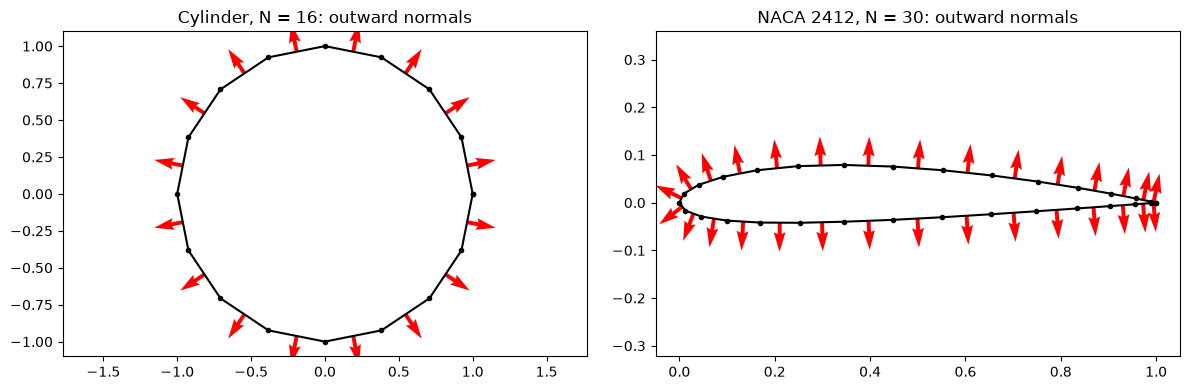

In [28]:
XB, YB = cylinder_boundary_points(4)
XC, YC, S, phi = panel_geometry(XB, YB)
print("S         =", np.round(S, 4))
print("phi (deg) =", np.round(np.degrees(phi), 1))
print("XC, YC    =", np.round(XC, 3), np.round(YC, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (XB, YB, title) in zip(ax, [(*cylinder_boundary_points(16), 'Cylinder, N = 16'),
                                   (*naca4_boundary_points('2412', 30), 'NACA 2412, N = 30')]):
    XC, YC, S, phi = panel_geometry(XB, YB)
    a.plot(XB, YB, 'ko-', ms=3)
    a.quiver(XC, YC, -np.sin(phi), np.cos(phi), color='r')
    a.set_title(title + ': outward normals'); a.axis('equal')
plt.tight_layout(); plt.show()

In [29]:
XB, YB = cylinder_boundary_points(16)
XC, YC, S, phi = panel_geometry(XB, YB)
J, K = compute_JK(XC, YC, XB, YB, phi, S)
print("J[0, 0:5]    =", np.round(J[0, 0:5], 5))
print("J[3, 3:8]    =", np.round(J[3, 3:8], 5), " (same as row 0: symmetry)")
print("row sums of J =", np.round(J.sum(axis=1)[:3], 10), " (uniform sheet gives no normal flow)")

J[0, 0:5]    = [ 0.      -1.09956 -0.4912  -0.30086 -0.20021]
J[3, 3:8]    = [ 0.      -1.09956 -0.4912  -0.30086 -0.20021]  (same as row 0: symmetry)
row sums of J = [-0. -0. -0.]  (uniform sheet gives no normal flow)


## 3. Verification: circular cylinder

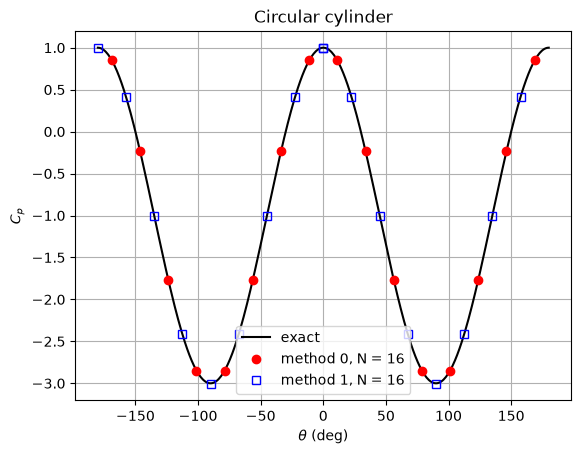

Gamma: method 0 = -0.0   method 1 = -0.0
max Cp error, method 0 = 6.661338147750939e-15


In [30]:
N = 16
XB, YB = cylinder_boundary_points(N)
r0 = vortex_panel_method_0(XB, YB, 0.0, kutta=False)
r1 = vortex_panel_method_1(XB, YB, 0.0, kutta=False)
th0 = np.arctan2(r0['YC'], r0['XC'])
th1 = np.arctan2(YB, XB)

th = np.linspace(-np.pi, np.pi, 400)
plt.plot(np.degrees(th), 1 - 4*np.sin(th)**2, 'k-', label='exact')
plt.plot(np.degrees(th0), r0['Cp'], 'ro', label=f'method 0, N = {N}')
plt.plot(np.degrees(th1), r1['Cp'], 'bs', mfc='none', label=f'method 1, N = {N}')
plt.xlabel(r'$\theta$ (deg)'); plt.ylabel('$C_p$'); plt.title('Circular cylinder')
plt.legend(); plt.grid(True); plt.show()

print("Gamma: method 0 =", round(r0['Gamma'], 12), "  method 1 =", round(r1['Gamma'], 12))
print("max Cp error, method 0 =", np.abs(r0['Cp'] - (1 - 4*np.sin(th0)**2)).max())

N =   16   method 0: 1.73e-01   method 1: 1.15e-03
N =   32   method 0: 8.69e-02   method 1: 1.59e-04
N =   64   method 0: 4.34e-02   method 1: 2.08e-05
N =  128   method 0: 2.17e-02   method 1: 2.67e-06


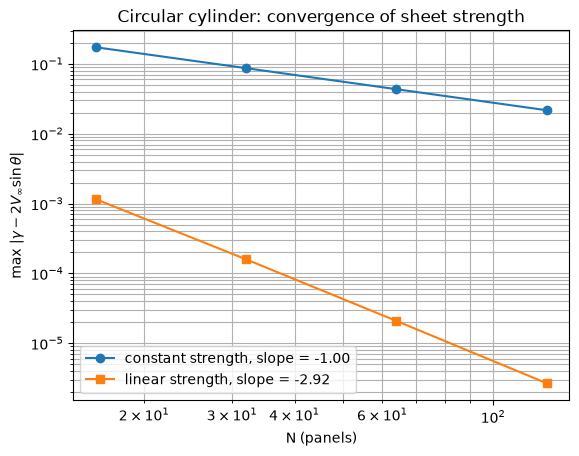

In [31]:
Ns = [16, 32, 64, 128]
err0, err1 = [], []
for N in Ns:
    XB, YB = cylinder_boundary_points(N)
    r0 = vortex_panel_method_0(XB, YB, 0.0, kutta=False)
    th0 = np.arctan2(r0['YC'], r0['XC'])
    err0.append(np.abs(r0['gamma'] - 2*np.sin(th0)).max())
    r1 = vortex_panel_method_1(XB, YB, 0.0, kutta=False)
    th1 = np.arctan2(YB, XB)
    err1.append(np.abs(r1['gamma'] - 2*np.sin(th1)).max())
    print(f"N = {N:4d}   method 0: {err0[-1]:.2e}   method 1: {err1[-1]:.2e}")

s0 = np.polyfit(np.log(Ns), np.log(err0), 1)[0]
s1 = np.polyfit(np.log(Ns), np.log(err1), 1)[0]
plt.loglog(Ns, err0, 'o-', label=f'constant strength, slope = {s0:.2f}')
plt.loglog(Ns, err1, 's-', label=f'linear strength, slope = {s1:.2f}')
plt.xlabel('N (panels)'); plt.ylabel(r'max $|\gamma - 2V_\infty\sin\theta|$')
plt.title('Circular cylinder: convergence of sheet strength')
plt.legend(); plt.grid(True, which='both'); plt.show()


### 3.1 Discussion

* **Building blocks.** The 4-panel geometry matches the hand calculation, and every normal points outward. On the 16-panel cylinder, every row of $J$ is a shifted copy of the first row (rotational symmetry), and each row sums to zero. A uniform vortex sheet on a closed body induces no normal velocity, so the zero row sums are the expected physical result. These checks verify the influence coefficients independently of the solver.
* **Pressure distribution.** Both methods reproduce the exact result $C_p = 1 - 4\sin^2\theta$, and the computed circulation is zero. For the constant-strength method, the agreement at the control points is at round-off level ($10^{-14}$) even with 16 panels. This is a special property of a regular polygon with midpoint control points, not evidence that the method is exact, so $C_p$ cannot be used to measure convergence on a cylinder.
* **Convergence.** The error in the sheet strength, compared with the exact $\gamma = 2V_\infty\sin\theta$, measures how much flow leaks inside the discrete body. Doubling $N$ halves the error of the constant-strength method (observed slope $-1.00$, first order). The linear-strength method error falls by a factor of about 8 per doubling (observed slope $\approx -2.9$ on this highly symmetric body). With 16 panels, the linear method is already more accurate than the constant method with 128 panels.
* **Singular matrix.** For a closed body, $J$ is singular: adding a constant $\gamma$ to every panel changes nothing. For even $N$, the sawtooth pattern $(+a, -a, \dots)$ is also an exact null mode. Replacing one equation therefore fails ("singular matrix" at $N = 64$). Appending the zero-circulation row and solving by least squares removes both modes.

## 4. Verification: airfoils

### 4.1 Panel distributions

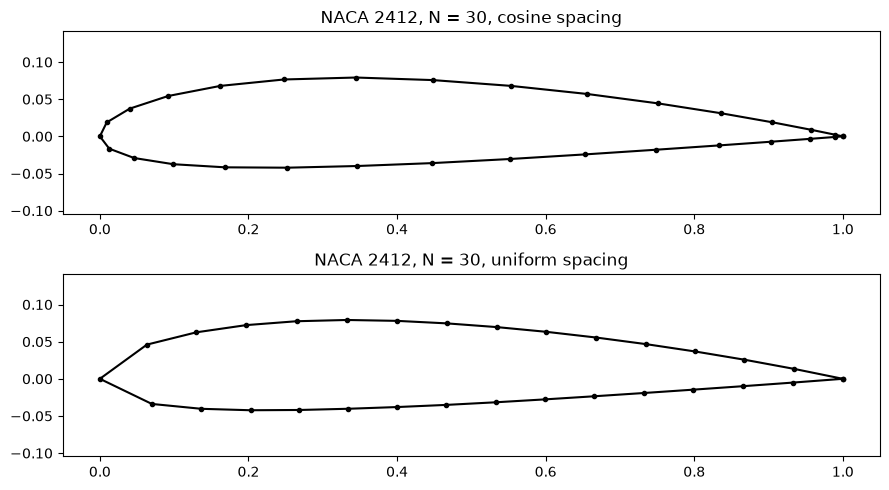

In [32]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5))
for k, sp in enumerate(['cosine', 'uniform']):
    XB, YB = naca4_boundary_points('2412', 30, sp)
    ax[k].plot(XB, YB, 'ko-', ms=3)
    ax[k].set_title(f'NACA 2412, N = 30, {sp} spacing'); ax[k].axis('equal')
plt.tight_layout(); plt.show()

4.2 Constant-strength method: the sawtooth mode

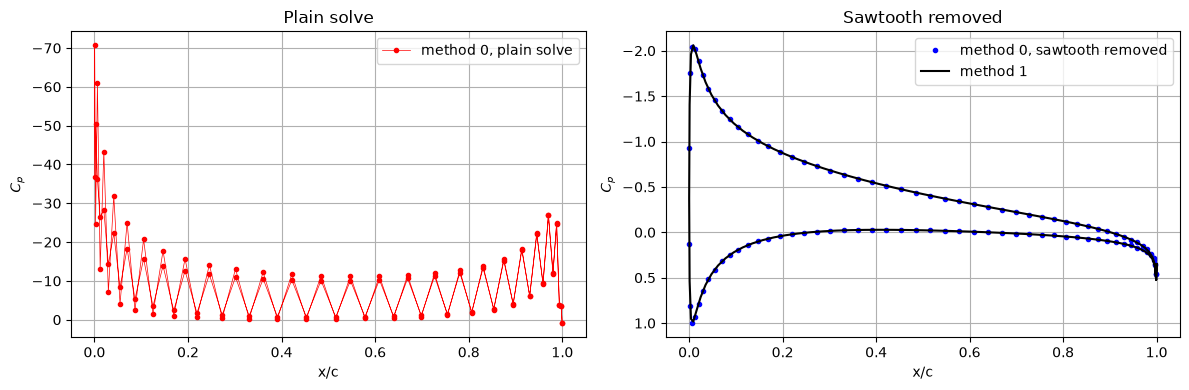

Cl: plain 0.6048   fixed 0.6051   linear 0.6028


In [33]:
XB, YB = naca4_boundary_points('0012', 100)
raw   = vortex_panel_method_0(XB, YB, 5.0, remove_sawtooth=False)
fixed = vortex_panel_method_0(XB, YB, 5.0, remove_sawtooth=True)
lin   = vortex_panel_method_1(XB, YB, 5.0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(raw['XC'], raw['Cp'], 'r.-', lw=0.5, label='method 0, plain solve')
ax[0].set_title('Plain solve')
ax[1].plot(fixed['XC'], fixed['Cp'], 'b.', label='method 0, sawtooth removed')
ax[1].plot(lin['XB'], lin['Cp'], 'k-', label='method 1')
ax[1].set_title('Sawtooth removed')
for a in ax:
    a.invert_yaxis(); a.set_xlabel('x/c'); a.set_ylabel('$C_p$'); a.legend(); a.grid(True)
plt.tight_layout(); plt.show()
print("Cl: plain", round(raw['Cl'], 4), "  fixed", round(fixed['Cl'], 4), "  linear", round(lin['Cl'], 4))

4.3 Convergence: number of panels and panel distribution


NACA 0012: reference Cl (method 1, N = 320) = 0.6030
  cosine   method 0:  Cl = [0.8705 0.6438 0.6053 0.605 ]   (35 s)
  cosine   method 1:  Cl = [0.5982 0.6017 0.6027 0.6029]   (43 s)
  uniform  method 0:  Cl = [0.6143 0.9981 1.0332 0.9479]   (51 s)
  uniform  method 1:  Cl = [0.5879 0.5956 0.5995 0.6014]   (60 s)
NACA 2412: reference Cl (method 1, N = 320) = 0.8616
  cosine   method 0:  Cl = [1.1282 0.9092 0.8614 0.8649]   (94 s)
  cosine   method 1:  Cl = [0.8523 0.8592 0.8611 0.8615]   (103 s)
  uniform  method 0:  Cl = [0.7802 1.1713 1.2388 1.1785]   (111 s)
  uniform  method 1:  Cl = [0.8333 0.8481 0.8553 0.8587]   (119 s)


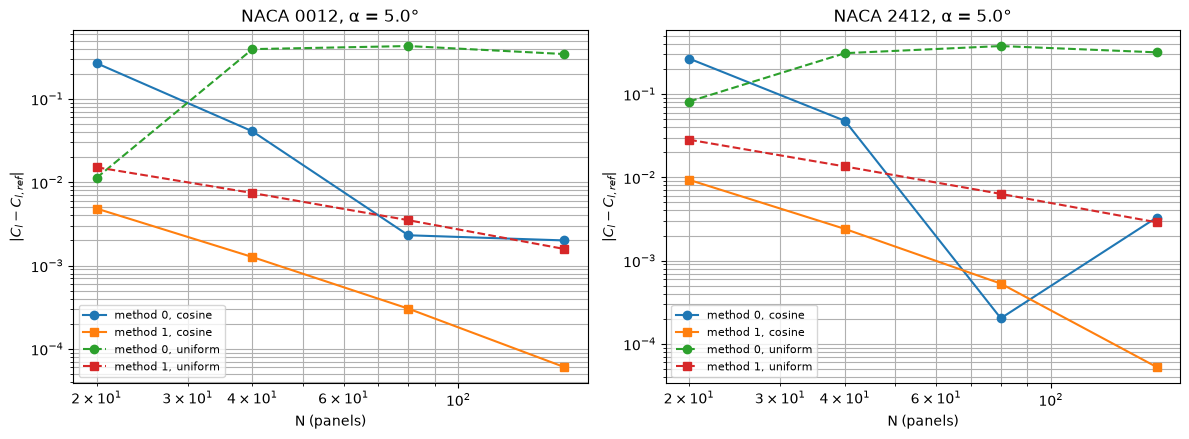

In [34]:
alpha = 5.0
Ns = [20, 40, 80, 160]
results = {}
t0 = time.time()

for code in ['0012', '2412']:
    XB, YB = naca4_boundary_points(code, 320, 'cosine')
    Cl_ref = vortex_panel_method_1(XB, YB, alpha)['Cl']
    print(f"NACA {code}: reference Cl (method 1, N = 320) = {Cl_ref:.4f}", flush=True)
    for spacing in ['cosine', 'uniform']:
        for name, solver in [('method 0', vortex_panel_method_0),
                             ('method 1', vortex_panel_method_1)]:
            Cl = []
            for N in Ns:
                XB, YB = naca4_boundary_points(code, N, spacing)
                Cl.append(solver(XB, YB, alpha)['Cl'])
            results[(code, spacing, name)] = np.abs(np.array(Cl) - Cl_ref)
            print(f"  {spacing:8s} {name}:  Cl = {np.round(Cl, 4)}"
                  f"   ({time.time()-t0:.0f} s)", flush=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, code in enumerate(['0012', '2412']):
    for (c, spacing, name), err in results.items():
        if c == code:
            style = '-' if spacing == 'cosine' else '--'
            mark = 'o' if name == 'method 0' else 's'
            ax[k].loglog(Ns, err, style + mark, label=f'{name}, {spacing}')
    ax[k].set_title(f'NACA {code}, α = {alpha}°')
    ax[k].set_xlabel('N (panels)'); ax[k].set_ylabel(r'$|C_l - C_{l,ref}|$')
    ax[k].grid(True, which='both'); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.4 Discussion

**Effect of the number of panels.** The reference value is the linear-strength result with 320 cosine-spaced panels ($c_l = 0.6030$ for NACA 0012 and $0.8616$ for NACA 2412 at $\alpha = 5^\circ$).
* With cosine spacing, the linear-strength method converges smoothly at roughly second order. Even at $N = 20$ its error is below 1.1 %.
* The constant-strength method needs $N \gtrsim 80$. At $N = 20$ it overpredicts $c_l$ by about 45 % (0.87 instead of 0.60). Above $N = 80$ it settles within about 0.3 % of the reference, but it converges irregularly.

**Sawtooth mode of the constant-strength method (Section 4.2).** With Anderson's plain solve, $c_l$ is reasonable, but $C_p$ oscillates violently from panel to panel, reaching $C_p \approx -70$ at $N = 100$. The cause is the same sawtooth mode met on the cylinder. On an airfoil it is no longer exactly singular, but its singular value is only about $10^{-5}$ of the largest, and the Kutta condition does not remove it. Dropping this single mode in an SVD solve gives a smooth $C_p$ that agrees with the linear-strength method, and changes $c_l$ by less than 0.1 %. Because $c_l$ is an integrated quantity, the alternating errors largely cancel in it, while $C_p$ shows them in full. The linear-strength method does not need this remedy: its $\gamma$ is continuous, no equation is discarded, and its matrix is well conditioned.

**Effect of panel distribution.** Uniform spacing gives the same panel width in $x$ everywhere. Near the leading edge, where $y \propto \sqrt{x}$, this produces a few long, steep panels and an artificial corner at the nose.
* For the linear method, convergence drops to first order, and $C_p$ at the nose node shows a spurious spike ($C_p \approx -16$ to $-24$).
* The constant-strength method with uniform spacing does not converge at all: $c_l$ wanders between 0.6 and 1.2.

Cosine spacing places small panels where the curvature and velocity gradients are largest (leading edge) and where the Kutta condition is applied (trailing edge), and it is used for all remaining results.

## 5. Prediction of airfoil characteristics

### 5.1 Lift and moment curves

NACA 0012 method 0: a0 = 6.906 /rad,  alpha_L0 = -0.00 deg
   alpha   Cl(K-J)  Cl(Cp)    Cd       Cm_c/4
   -4.0000  -0.4838  -0.4803  -0.0001   0.0050
   -2.0000  -0.2419  -0.2402  -0.0001   0.0025
    0.0000   0.0003   0.0003  -0.0001  -0.0001
    2.0000   0.2424   0.2407  -0.0001  -0.0026
    4.0000   0.4843   0.4808  -0.0001  -0.0051
    6.0000   0.7256   0.7204  -0.0001  -0.0076
    8.0000   0.9661   0.9591  -0.0001  -0.0101
   10.0000   1.2053   1.1966  -0.0000  -0.0125
   12.0000   1.4431   1.4326   0.0000  -0.0149
NACA 0012 method 1: a0 = 6.883 /rad,  alpha_L0 = 0.00 deg
   alpha   Cl(K-J)  Cl(Cp)    Cd       Cm_c/4
   -4.0000  -0.4825  -0.4819  -0.0004   0.0057
   -2.0000  -0.2414  -0.2411  -0.0005   0.0028
    0.0000  -0.0000  -0.0000  -0.0005   0.0000
    2.0000   0.2414   0.2411  -0.0005  -0.0028
    4.0000   0.4825   0.4819  -0.0004  -0.0057
    6.0000   0.7230   0.7221  -0.0002  -0.0085
    8.0000   0.9626   0.9614   0.0000  -0.0112
   10.0000   1.2010   1.1995   0.0003  

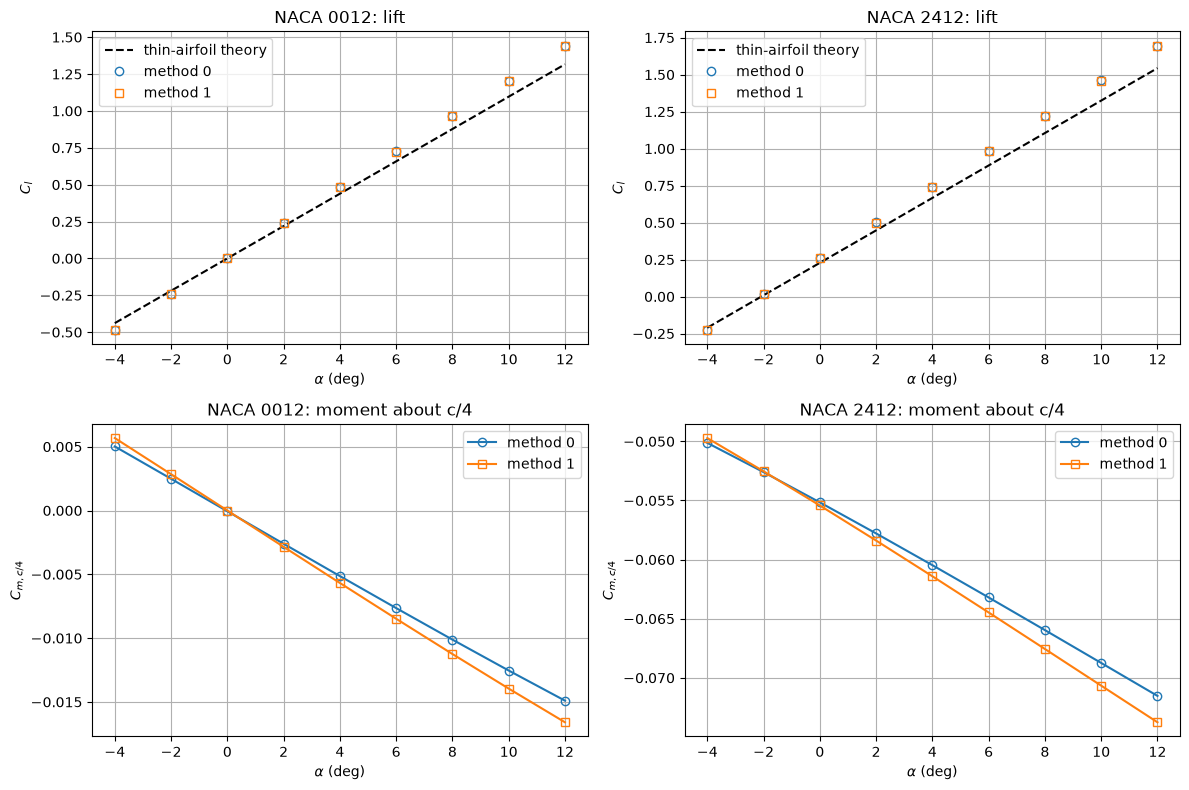

In [35]:
alphas = np.arange(-4, 13, 2.0)
N = 100
polar = {}

for code in ['0012', '2412']:
    XB, YB = naca4_boundary_points(code, N)
    for name, solver in [('method 0', vortex_panel_method_0),
                         ('method 1', vortex_panel_method_1)]:
        rows = []
        for a in alphas:
            r = solver(XB, YB, a)
            xp, yp, Cp = panel_Cp(r)
            Cl_p, Cd_p, Cm = forces_from_Cp(xp, yp, Cp, r['S'], r['phi'], a)
            rows.append([a, r['Cl'], Cl_p, Cd_p, Cm])
        rows = np.array(rows)
        polar[(code, name)] = rows
        slope, icpt = np.polyfit(np.radians(rows[:, 0]), rows[:, 1], 1)
        print(f"NACA {code} {name}: a0 = {slope:.3f} /rad,  "
              f"alpha_L0 = {-np.degrees(icpt/slope):.2f} deg")
        print("   alpha   Cl(K-J)  Cl(Cp)    Cd       Cm_c/4")
        for row in rows:
            print("   " + "  ".join(f"{v:7.4f}" for v in row))

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
a_line = np.linspace(-4, 12, 50)
for k, (code, aL0) in enumerate([('0012', 0.0), ('2412', -2.08)]):
    ax[0, k].plot(a_line, 2*np.pi*np.radians(a_line - aL0), 'k--', label='thin-airfoil theory')
    for name, mk in [('method 0', 'o'), ('method 1', 's')]:
        rows = polar[(code, name)]
        ax[0, k].plot(rows[:, 0], rows[:, 1], mk, mfc='none', label=name)
        ax[1, k].plot(rows[:, 0], rows[:, 4], mk + '-', mfc='none', label=name)
    ax[0, k].set_title(f'NACA {code}: lift'); ax[0, k].set_ylabel('$C_l$')
    ax[1, k].set_title(f'NACA {code}: moment about c/4'); ax[1, k].set_ylabel('$C_{m,c/4}$')
    for a in ax[:, k]:
        a.set_xlabel(r'$\alpha$ (deg)'); a.grid(True); a.legend()
plt.tight_layout(); plt.show()

### 5.2 Pressure distributions

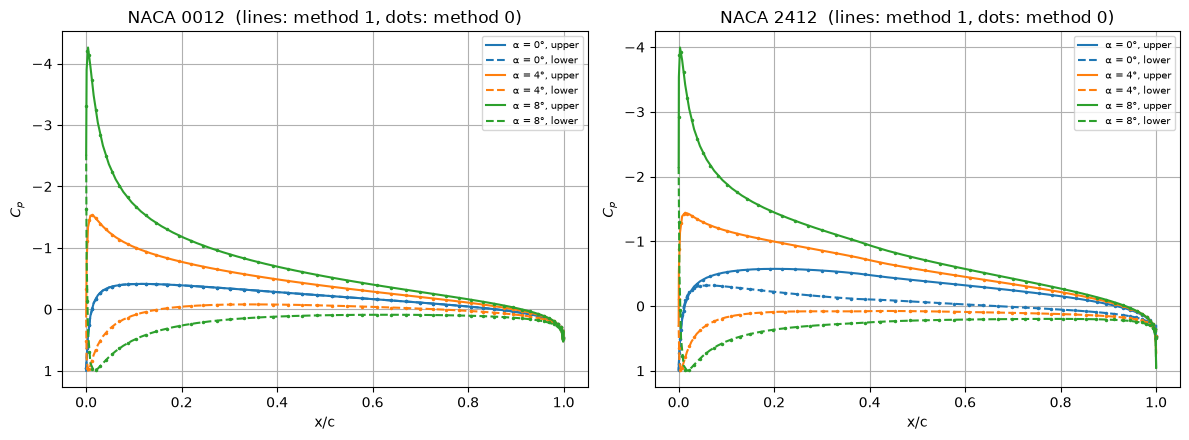

In [36]:
N = 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for k, code in enumerate(['0012', '2412']):
    XB, YB = naca4_boundary_points(code, N)
    h = N//2
    for a, col in [(0, 'C0'), (4, 'C1'), (8, 'C2')]:
        r = vortex_panel_method_1(XB, YB, a)
        ax[k].plot(XB[h:], r['Cp'][h:], '-',  color=col, label=f'α = {a}°, upper')
        ax[k].plot(XB[:h+1], r['Cp'][:h+1], '--', color=col, label=f'α = {a}°, lower')
        r0 = vortex_panel_method_0(XB, YB, a)
        ax[k].plot(r0['XC'], r0['Cp'], '.', color=col, ms=3)
    ax[k].invert_yaxis()
    ax[k].set_title(f'NACA {code}  (lines: method 1, dots: method 0)')
    ax[k].set_xlabel('x/c'); ax[k].set_ylabel('$C_p$')
    ax[k].grid(True); ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5.3 Comparison with experiment

The cell below compares the predictions with measured section characteristics. **Enter the experimental values** from Abbott & von Doenhoff, *Theory of Wing Sections*, Appendix IV (smooth model, $Re = 6\times10^6$), and rerun the cell. The table prints the panel-method values next to them.

In [37]:
experiment = {
    '0012': dict(a0_deg=None, alpha_L0=None, cl_max=None, cm_c4=None),
    '2412': dict(a0_deg=None, alpha_L0=None, cl_max=None, cm_c4=None),
}

print(f"{'':6s} {'':14s} {'a0 (/deg)':>10s} {'alpha_L0':>9s} {'cl_max':>7s} {'cm_c/4':>7s}")
for code in ['0012', '2412']:
    rows = polar[(code, 'method 1')]
    a0, icpt = np.polyfit(rows[:, 0], rows[:, 1], 1)
    aL0 = -icpt/a0
    cm0 = np.interp(aL0, rows[:, 0], rows[:, 4])
    print(f"{code:6s} {'panel method':14s} {a0:10.4f} {aL0:9.2f} {'none':>7s} {cm0:7.3f}")
    e = experiment[code]
    fmt = lambda v, f: (f % v) if v is not None else '—'
    print(f"{code:6s} {'experiment':14s} {fmt(e['a0_deg'], '%10.4f'):>10s} "
          f"{fmt(e['alpha_L0'], '%9.2f'):>9s} {fmt(e['cl_max'], '%7.2f'):>7s} {fmt(e['cm_c4'], '%7.3f'):>7s}")

                       a0 (/deg)  alpha_L0  cl_max  cm_c/4
0012   panel method       0.1201      0.00    none  -0.000
0012   experiment              —         —       —       —
2412   panel method       0.1198     -2.16    none  -0.052
2412   experiment              —         —       —       —


### 5.4 Discussion

* **Lift-curve slope.** Both methods give $a_0 \approx 6.87$–$6.91$ per radian ($0.120$ per degree) for both sections. This is higher than the thin-airfoil value $2\pi = 6.28$ because thickness increases the inviscid lift slope. The estimate $a_0 \approx 2\pi(1 + 0.77\, t/c) = 6.86$ for $t/c = 0.12$ agrees within 0.5 %.
* **Zero-lift angle.** The NACA 0012 gives $\alpha_{L0} = 0^\circ$, as symmetry requires. The NACA 2412 gives $\alpha_{L0} = -2.16^\circ$, close to the thin-airfoil value $-2.08^\circ$, which accounts only for the camber line.
* **Pitching moment.** The 2412 has $c_{m,c/4} \approx -0.052$ at zero lift ($-0.055$ at $\alpha = 0^\circ$), a nose-down moment due to camber, close to the thin-airfoil value of about $-0.053$. $c_{m,c/4}$ varies only slightly with $\alpha$, so the inviscid aerodynamic centre lies close to the quarter chord (about $0.26c$).
* **Two independent lift calculations.** The circulation ($c_l = 2\Gamma/V_\infty c$) and the pressure integration agree within about 1 %. The pressure drag is $|c_d| \lesssim 10^{-3}$, i.e. zero to discretisation accuracy. This is d'Alembert's paradox, and it confirms the pressure integration. Real sections have a profile drag of about 0.006 even at low lift.
* **Pressure distributions.** Increasing $\alpha$ moves the stagnation point ($C_p = 1$) onto the lower surface and builds a sharp suction peak just behind the leading edge on the upper surface, followed by a long adverse pressure gradient. The NACA 2412 has a finite pressure difference at $\alpha = 0^\circ$ (lift due to camber), and its suction peak is weaker than that of the 0012 at the same $c_l$. At the trailing edge both surfaces reach the same $C_p$: the Kutta condition is satisfied. The constant-strength results (dots) lie on the linear-strength curves.
* **Comparison with experiment.** The measured lift slope is lower than the inviscid prediction, because the boundary layer displaces the effective shape and reduces the circulation, and measured sections stall at a finite $c_{l,\max}$. The panel method predicts a straight line with no stall at any angle. The predicted $\alpha_{L0}$ and $c_{m,c/4}$ are usually close to experiment because they depend mostly on camber.

## 6. Limitations of prediction: effect of thickness

Panel methods solve inviscid, irrotational flow. Viscous effects enter real flows through the boundary layer, which must climb the adverse pressure gradient behind the suction peak. Thicker sections produce stronger and longer rear-surface pressure rises, so the boundary layer thickens and eventually separates near the trailing edge. The flow then no longer leaves the trailing edge as assumed by the Kutta condition, and the inviscid prediction loses accuracy.

The functions are applied to the symmetric NACA 00xx family, $t/c = 6\,\%$ to $30\,\%$, with 100 cosine-spaced panels.

### 6.1 Lift-curve slope against thickness

 t/c    a0 method 0   a0 method 1   2pi(1+0.77 t/c)   (per rad)
  6 %        6.764        6.576          6.573
  9 %        6.763        6.735          6.719
 12 %        6.917        6.894          6.864
 15 %        7.083        7.054          7.009
 18 %        7.248        7.215          7.154
 21 %        7.413        7.377          7.299
 24 %        7.578        7.539          7.444
 30 %        7.910        7.867          7.735


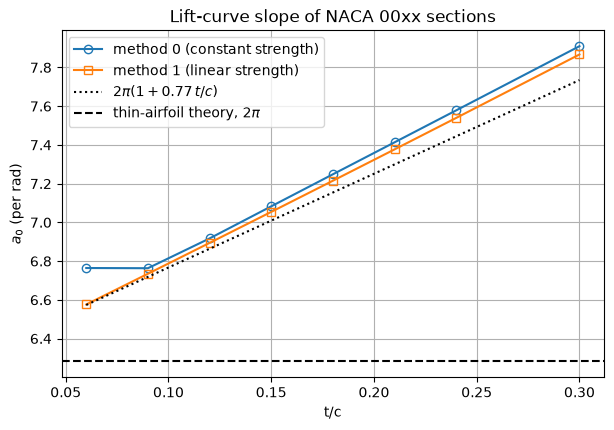

In [38]:
thick = [6, 9, 12, 15, 18, 21, 24, 30]
N = 100
a0_m0, a0_m1 = [], []
for t in thick:
    XB, YB = naca4_boundary_points(f'00{t:02d}', N)
    for solver, store in [(vortex_panel_method_0, a0_m0), (vortex_panel_method_1, a0_m1)]:
        Cl0 = solver(XB, YB, 0.0)['Cl']
        Cl8 = solver(XB, YB, 8.0)['Cl']
        store.append((Cl8 - Cl0)/np.radians(8.0))

tc = np.array(thick)/100
print(" t/c    a0 method 0   a0 method 1   2pi(1+0.77 t/c)   (per rad)")
for t, a, b in zip(thick, a0_m0, a0_m1):
    print(f"{t:3d} %   {a:10.3f}   {b:10.3f}   {2*np.pi*(1 + 0.77*t/100):12.3f}")

experiment_a0 = {6: None, 9: None, 12: None, 15: None, 18: None, 21: None, 24: None}

plt.figure(figsize=(7, 4.5))
plt.plot(tc, a0_m0, 'o-', mfc='none', label='method 0 (constant strength)')
plt.plot(tc, a0_m1, 's-', mfc='none', label='method 1 (linear strength)')
plt.plot(tc, 2*np.pi*(1 + 0.77*tc), 'k:', label=r'$2\pi(1 + 0.77\,t/c)$')
plt.axhline(2*np.pi, color='k', ls='--', label=r'thin-airfoil theory, $2\pi$')
ex = [(t/100, np.degrees(1)*v) for t, v in experiment_a0.items() if v is not None]
if ex:
    plt.plot(*zip(*ex), 'r^', ms=8, label='experiment (Abbott & von Doenhoff)')
plt.xlabel('t/c'); plt.ylabel(r'$a_0$ (per rad)')
plt.title('Lift-curve slope of NACA 00xx sections')
plt.grid(True); plt.legend(); plt.show()